<h1><center>Data Wrangling: Handling Missing Data, Identifying Outliers and Visualization</center></h1>
<h2 style="text-align:center;">Author: Dr. Suborna Ahmed</h2>

 ***


## Introduction
In this chapter, we will delve into the fundamental concepts of missing data. You will learn how to identify missing data and explore methods to handle it, including filtering out missing values and filling in the gaps using appropriate techniques. Throughout the chapter, you will find a series of practice questions designed to help you apply the methods and techniques discussed. These questions will allow you to reinforce your understanding and gain hands-on experience in working with real-world datasets. So, by actively engaging with the practice questions, solidify your knowledge and develop confidence in utilizing these skills in your data analysis endeavors.

#### Learning Objectives
1. Subsetting and Aggregating Data
   * Subsetting Datasets by Row and Column
   * Subsetting Datasets Using a Conditional Statement
   * Aggregations (Group By)
2. Handling Missing Data
   * Understanding why data is missing and missing data types
   * Identifying missing data
   * Filtering out missing data
   * Filling in missing data
   * Data Types and Conversion
3. Detecting Outliers and Anomalies
4. Data Exploration and Summarization

#### Readings
- Read [Kuhn & Johnson (2013) Applied Predictive Modeling](https://link.springer.com/content/pdf/10.1007/978-1-4614-6849-3.pdf) section 3.4 dealing with missing values. This section offers a good overview of the theoretical problems to think of when dealing with datasets that are missing values (a very brief summary of which is below).

- Additionally, the official [Pandas Cheatsheet](https://pandas.pydata.org/Pandas_Cheat_Sheet.pdf) could be very handy throughout this book!!

#### References

* [McKinney, W. 2022. Python for Data Analysis, 3st edition. O'Reilly, Sebastopol, United States](https://wesmckinney.com/book/):
    * Chapter 5. Getting Started with pandas
    * Chapter 7.  Data Cleaning and Preparation
    * Chapter 8. Data Wrangling: Join, Combine, and Reshape

#### Required Packages

The following code cell includes all the necessary packages to complete this chapter. It is a good idea to run this right now to make sure you have no issues.

In [1]:
#import needed packages

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

#### Required Datasets
1. airdata3.csv - originally downloaded from https://envistaweb.env.gov.bc.ca/

# 1. Prelude - Subsetting and Aggregating Data

We are using the Pandas library. The developers had the following philosophy and ideas in mind when they developed Pandas:
* Provision of a comprehensive framework for statistical analysis and modelling in Python.
* Handling complex datasets in tabular (2D) format.
* Implementing SQL-like querying and aggregating.
* Integration with the Data Science stack in python (e.g. matplotlib, seaborn, scikit-learn).

Before we get started with handling missing data, identifying outliers, and scaling variables, we would like to introduce key tools for selecting subsets of datasets and data aggregation.

If you are familiar with this you can sit back for now...



## 1.1 Subsetting Datasets by Row and Column
Data tables can be subsetted by selecting specific rows and columns, either by name or index.

There are two main methods for selecting rows and columns:
* **loc** = Locator. We need to specify the names of the rows and columns that we want to subset.
* **iloc** = Integer Locator. We need to specify the rows and columns we want to subset by their integer index.

Let's try it...

We are going to use a data set that was custom downloaded for this activity from https://envistaweb.env.gov.bc.ca/. The data set ("airdata3.csv") consists of air quality and other environmental variables, measured by various air monitoring stations in the Greater Vancouver area. Measurements were taken every hour, for the month of January in the year 2000.

We must read in the data using [pd.read_csv()](https://pandas.pydata.org/docs/reference/api/pandas.read_csv.html).

In [2]:
from google.colab import drive
drive.mount('/content/drive/')

Drive already mounted at /content/drive/; to attempt to forcibly remount, call drive.mount("/content/drive/", force_remount=True).


In [3]:
#using pd.read_csv to read in the data

data = pd.read_csv('/content/drive/MyDrive/FRST505/week4/airdata3.csv')

In [4]:
# Lets get an idea of what's in there
# Column names:
data.columns

Index(['Unnamed: 0.1', 'Unnamed: 0', 'WSPD_VECT', 'WDIR_SCLR', 'WSPD_SCLR',
       'PM10', 'SO2', 'NOx', 'WDIR_VECT', 'TEMP_MEAN', 'CO', 'NO', 'NO2',
       'PM25', 'PRECIP_TOTAL', 'O3', 'ATM_PRESS_1HR', 'HUMIDITY', 'location',
       'Date', 'Time', 'RAD_TOTAL', 'NH3', 'PM25_5030i', 'TRS', 'RAD_NET',
       'PM25_SHARP'],
      dtype='object')

In [5]:
# First 5 rows
data.head(5)

,Unnamed: 0.1,Unnamed: 0,WSPD_VECT,WDIR_SCLR,WSPD_SCLR,PM10,SO2,NOx,WDIR_VECT,TEMP_MEAN,...,HUMIDITY,location,Date,Time,RAD_TOTAL,NH3,PM25_5030i,TRS,RAD_NET,PM25_SHARP
0,0,1,NaN,NaN,NaN,13.0,0.0,NaN,NaN,NaN,...,NaN,Burnaby South,1/1/2000,1:00 AM,NaN,NaN,NaN,NaN,NaN,NaN
1,1,2,NaN,NaN,NaN,6.0,0.0,NaN,NaN,NaN,...,NaN,Burnaby South,1/1/2000,2:00 AM,NaN,NaN,NaN,NaN,NaN,NaN
2,2,3,NaN,NaN,NaN,2.0,0.0,NaN,NaN,NaN,...,NaN,Burnaby South,1/1/2000,3:00 AM,NaN,NaN,NaN,NaN,NaN,NaN
3,3,4,NaN,NaN,NaN,2.0,0.0,NaN,NaN,NaN,...,NaN,Burnaby South,1/1/2000,4:00 AM,NaN,NaN,NaN,NaN,NaN,NaN
4,4,5,NaN,NaN,NaN,4.0,0.0,NaN,NaN,NaN,...,NaN,Burnaby South,1/1/2000,5:00 AM,NaN,NaN,NaN,NaN,NaN,NaN


### .loc[] and .iloc[] explained
Both .loc and .iloc are methods that can be used directly on a DataFrame. Note that the arguments are put within square brackets. Odd, isn't it? These are usually round with other methods.

.loc takes two arguments: row name and row column. If you would like to select multiple columns or rows you can provide a list of names. Alternatively, if you would like to select all columns or rows use the slice operator ":". The slicing operator also allows selection of multiple rows or corners in consecutive order.

### Syntax
.loc[row name, column name]

In [6]:
# Subset: All rows and two columns
data.loc[:,['PM10','SO2']]

,PM10,SO2
0,13.0,0.0
1,6.0,0.0
2,2.0,0.0
3,2.0,0.0
4,4.0,0.0
...,...,...
11899,NaN,NaN
11900,NaN,NaN
11901,NaN,NaN
11902,NaN,NaN


In [7]:
# Subset: All rows and multiple columns specified using a slice operator
data.loc[:,'PM10':'NO']

,PM10,SO2,NOx,WDIR_VECT,TEMP_MEAN,CO,NO
0,13.0,0.0,NaN,NaN,NaN,0.5,10.0
1,6.0,0.0,NaN,NaN,NaN,0.4,4.0
2,2.0,0.0,NaN,NaN,NaN,0.4,2.0
3,2.0,0.0,NaN,NaN,NaN,0.3,1.0
4,4.0,0.0,NaN,NaN,NaN,0.3,1.0
...,...,...,...,...,...,...,...
11899,NaN,NaN,NaN,NaN,NaN,NaN,NaN
11900,NaN,NaN,NaN,NaN,NaN,NaN,NaN
11901,NaN,NaN,NaN,NaN,NaN,NaN,NaN
11902,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [8]:
# Subset: First 10 rows and multiple columns specified using a slice operator.
data.loc[1:10,'PM10':'NO']


,PM10,SO2,NOx,WDIR_VECT,TEMP_MEAN,CO,NO
1,6.0,0.0,NaN,NaN,NaN,0.4,4.0
2,2.0,0.0,NaN,NaN,NaN,0.4,2.0
3,2.0,0.0,NaN,NaN,NaN,0.3,1.0
4,4.0,0.0,NaN,NaN,NaN,0.3,1.0
5,2.0,0.0,NaN,NaN,NaN,0.3,1.0
6,4.0,0.0,NaN,NaN,NaN,0.3,1.0
7,6.0,0.0,NaN,NaN,NaN,0.4,1.0
8,6.0,0.0,NaN,NaN,NaN,0.4,2.0
9,8.0,0.0,NaN,NaN,NaN,0.4,5.0
10,7.0,0.0,NaN,NaN,NaN,0.4,4.0


Note the rows do not have names in this case... it's a numerical index. In this case you can just use integer indices in .loc

.iloc[] works exactly the same, but with integer indices. Check the examples below:

In [9]:
data.iloc[:,[4,5]]

,WSPD_SCLR,PM10
0,NaN,13.0
1,NaN,6.0
2,NaN,2.0
3,NaN,2.0
4,NaN,4.0
...,...,...
11899,NaN,NaN
11900,NaN,NaN
11901,NaN,NaN
11902,NaN,NaN


In [10]:
data.iloc[:,4:11]

,WSPD_SCLR,PM10,SO2,NOx,WDIR_VECT,TEMP_MEAN,CO
0,NaN,13.0,0.0,NaN,NaN,NaN,0.5
1,NaN,6.0,0.0,NaN,NaN,NaN,0.4
2,NaN,2.0,0.0,NaN,NaN,NaN,0.4
3,NaN,2.0,0.0,NaN,NaN,NaN,0.3
4,NaN,4.0,0.0,NaN,NaN,NaN,0.3
...,...,...,...,...,...,...,...
11899,NaN,NaN,NaN,NaN,NaN,NaN,NaN
11900,NaN,NaN,NaN,NaN,NaN,NaN,NaN
11901,NaN,NaN,NaN,NaN,NaN,NaN,NaN
11902,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 1.2 Subsetting Datasets Using a Conditional Statement

Alternatively, rows can be selected based on a condition, for a single or multiple columns. Comparison operators used to compare values and determine their relative order or equality. Figure 1 shows a brief explanation of these comparison operators:
<br>
<br>
<div style="text-align: center;">
<img src=https://i.imgur.com/d3nM4t1.png alt="image" width="450"/>
</div>
<div style="text-align: center;">
     <strong>Figure 1: Comparison Operators and Their Meanings</strong>
    </div>
    <br>
    <br>
The following code is an example of conditional statement on a single column:

In [11]:
# Select all rows having PM10 larger than 3. Retain all columns in output.
data.loc[data['PM10']>3,:]

# output has 278 rows

,Unnamed: 0.1,Unnamed: 0,WSPD_VECT,WDIR_SCLR,WSPD_SCLR,PM10,SO2,NOx,WDIR_VECT,TEMP_MEAN,...,HUMIDITY,location,Date,Time,RAD_TOTAL,NH3,PM25_5030i,TRS,RAD_NET,PM25_SHARP
0,0,1,NaN,NaN,NaN,13.0,0.0,NaN,NaN,NaN,...,NaN,Burnaby South,1/1/2000,1:00 AM,NaN,NaN,NaN,NaN,NaN,NaN
1,1,2,NaN,NaN,NaN,6.0,0.0,NaN,NaN,NaN,...,NaN,Burnaby South,1/1/2000,2:00 AM,NaN,NaN,NaN,NaN,NaN,NaN
4,4,5,NaN,NaN,NaN,4.0,0.0,NaN,NaN,NaN,...,NaN,Burnaby South,1/1/2000,5:00 AM,NaN,NaN,NaN,NaN,NaN,NaN
6,6,7,NaN,NaN,NaN,4.0,0.0,NaN,NaN,NaN,...,NaN,Burnaby South,1/1/2000,7:00 AM,NaN,NaN,NaN,NaN,NaN,NaN
7,7,8,NaN,NaN,NaN,6.0,0.0,NaN,NaN,NaN,...,NaN,Burnaby South,1/1/2000,8:00 AM,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11152,11152,737,NaN,NaN,NaN,9.0,5.0,NaN,NaN,NaN,...,NaN,Vancouver Kitsilano,1/31/2000,5:00 PM,NaN,NaN,NaN,NaN,NaN,NaN
11153,11153,738,NaN,NaN,NaN,6.0,4.0,NaN,NaN,NaN,...,NaN,Vancouver Kitsilano,1/31/2000,6:00 PM,NaN,NaN,NaN,NaN,NaN,NaN
11155,11155,740,NaN,NaN,NaN,4.0,0.0,NaN,NaN,NaN,...,NaN,Vancouver Kitsilano,1/31/2000,8:00 PM,NaN,NaN,NaN,NaN,NaN,NaN
11158,11158,743,NaN,NaN,NaN,4.0,2.0,NaN,NaN,NaN,...,NaN,Vancouver Kitsilano,1/31/2000,11:00 PM,NaN,NaN,NaN,NaN,NaN,NaN


In data analysis and programming, we often encounter situations where we need to create conditional statements using multiple columns or conditions. We can build conditional statements using multiple columns by using boolean operators. For example, we can select rows that have a PM10 measurement larger than 3 but also have SO2 levels above 4. The main boolean operators are AND, OR, and XOR. It can be tricky to understand them, but Figure 2 provides a clear understanding of the behavior and outcomes associated with boolean operators.
<br>
<br>
<br>
<div style="text-align: center;">
<img src=https://i.imgur.com/3txnJOs.png alt="image" width="350"/>
</div>
<br>
<div style="text-align: center;">
     <strong>Figure 2: Boolean Operators and Their Meanings</strong>
    </div>
    <br>
    <br>
Additionally, for further comprehension, you can refer to the following code examples:

In [12]:
# If we use AND, then both statements need to be valid
data.loc[(data['PM10']>3) & (data['SO2']>4),:]

# output has 278 rows

,Unnamed: 0.1,Unnamed: 0,WSPD_VECT,WDIR_SCLR,WSPD_SCLR,PM10,SO2,NOx,WDIR_VECT,TEMP_MEAN,...,HUMIDITY,location,Date,Time,RAD_TOTAL,NH3,PM25_5030i,TRS,RAD_NET,PM25_SHARP
61,61,62,NaN,NaN,NaN,5.0,1000.0,NaN,NaN,NaN,...,NaN,Burnaby South,1/3/2000,2:00 PM,NaN,NaN,NaN,NaN,NaN,NaN
155,155,156,NaN,NaN,NaN,13.0,5.0,NaN,NaN,NaN,...,NaN,Burnaby South,1/7/2000,12:00 PM,NaN,NaN,NaN,NaN,NaN,NaN
396,396,397,NaN,NaN,NaN,19.0,5.0,NaN,NaN,NaN,...,NaN,Burnaby South,1/17/2000,1:00 PM,NaN,NaN,NaN,NaN,NaN,NaN
397,397,398,NaN,NaN,NaN,19.0,5.0,NaN,NaN,NaN,...,NaN,Burnaby South,1/17/2000,2:00 PM,NaN,NaN,NaN,NaN,NaN,NaN
444,444,445,NaN,NaN,NaN,18.0,5.0,NaN,NaN,NaN,...,NaN,Burnaby South,1/19/2000,1:00 PM,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11141,11141,726,NaN,NaN,NaN,8.0,7.0,NaN,NaN,NaN,...,NaN,Vancouver Kitsilano,1/31/2000,6:00 AM,NaN,NaN,NaN,NaN,NaN,NaN
11142,11142,727,NaN,NaN,NaN,10.0,10.0,NaN,NaN,NaN,...,NaN,Vancouver Kitsilano,1/31/2000,7:00 AM,NaN,NaN,NaN,NaN,NaN,NaN
11150,11150,735,NaN,NaN,NaN,18.0,10.0,NaN,NaN,NaN,...,NaN,Vancouver Kitsilano,1/31/2000,3:00 PM,NaN,NaN,NaN,NaN,NaN,NaN
11151,11151,736,NaN,NaN,NaN,13.0,8.0,NaN,NaN,NaN,...,NaN,Vancouver Kitsilano,1/31/2000,4:00 PM,NaN,NaN,NaN,NaN,NaN,NaN


In [13]:
# If we use OR, then either of the statements needs to be valid.
data.loc[(data['PM10']>3) | (data['SO2']>4),:]

# output has 4157 rows

,Unnamed: 0.1,Unnamed: 0,WSPD_VECT,WDIR_SCLR,WSPD_SCLR,PM10,SO2,NOx,WDIR_VECT,TEMP_MEAN,...,HUMIDITY,location,Date,Time,RAD_TOTAL,NH3,PM25_5030i,TRS,RAD_NET,PM25_SHARP
0,0,1,NaN,NaN,NaN,13.0,0.0,NaN,NaN,NaN,...,NaN,Burnaby South,1/1/2000,1:00 AM,NaN,NaN,NaN,NaN,NaN,NaN
1,1,2,NaN,NaN,NaN,6.0,0.0,NaN,NaN,NaN,...,NaN,Burnaby South,1/1/2000,2:00 AM,NaN,NaN,NaN,NaN,NaN,NaN
4,4,5,NaN,NaN,NaN,4.0,0.0,NaN,NaN,NaN,...,NaN,Burnaby South,1/1/2000,5:00 AM,NaN,NaN,NaN,NaN,NaN,NaN
6,6,7,NaN,NaN,NaN,4.0,0.0,NaN,NaN,NaN,...,NaN,Burnaby South,1/1/2000,7:00 AM,NaN,NaN,NaN,NaN,NaN,NaN
7,7,8,NaN,NaN,NaN,6.0,0.0,NaN,NaN,NaN,...,NaN,Burnaby South,1/1/2000,8:00 AM,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11152,11152,737,NaN,NaN,NaN,9.0,5.0,NaN,NaN,NaN,...,NaN,Vancouver Kitsilano,1/31/2000,5:00 PM,NaN,NaN,NaN,NaN,NaN,NaN
11153,11153,738,NaN,NaN,NaN,6.0,4.0,NaN,NaN,NaN,...,NaN,Vancouver Kitsilano,1/31/2000,6:00 PM,NaN,NaN,NaN,NaN,NaN,NaN
11155,11155,740,NaN,NaN,NaN,4.0,0.0,NaN,NaN,NaN,...,NaN,Vancouver Kitsilano,1/31/2000,8:00 PM,NaN,NaN,NaN,NaN,NaN,NaN
11158,11158,743,NaN,NaN,NaN,4.0,2.0,NaN,NaN,NaN,...,NaN,Vancouver Kitsilano,1/31/2000,11:00 PM,NaN,NaN,NaN,NaN,NaN,NaN


In [14]:
# If we use XOR, then one and only one of the statements needs to be valid.
data.loc[(data['PM10'] > 3) ^ (data['SO2'] > 4), :]

# output has 3879 rows

,Unnamed: 0.1,Unnamed: 0,WSPD_VECT,WDIR_SCLR,WSPD_SCLR,PM10,SO2,NOx,WDIR_VECT,TEMP_MEAN,...,HUMIDITY,location,Date,Time,RAD_TOTAL,NH3,PM25_5030i,TRS,RAD_NET,PM25_SHARP
0,0,1,NaN,NaN,NaN,13.0,0.0,NaN,NaN,NaN,...,NaN,Burnaby South,1/1/2000,1:00 AM,NaN,NaN,NaN,NaN,NaN,NaN
1,1,2,NaN,NaN,NaN,6.0,0.0,NaN,NaN,NaN,...,NaN,Burnaby South,1/1/2000,2:00 AM,NaN,NaN,NaN,NaN,NaN,NaN
4,4,5,NaN,NaN,NaN,4.0,0.0,NaN,NaN,NaN,...,NaN,Burnaby South,1/1/2000,5:00 AM,NaN,NaN,NaN,NaN,NaN,NaN
6,6,7,NaN,NaN,NaN,4.0,0.0,NaN,NaN,NaN,...,NaN,Burnaby South,1/1/2000,7:00 AM,NaN,NaN,NaN,NaN,NaN,NaN
7,7,8,NaN,NaN,NaN,6.0,0.0,NaN,NaN,NaN,...,NaN,Burnaby South,1/1/2000,8:00 AM,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11149,11149,734,NaN,NaN,NaN,8.0,3.0,NaN,NaN,NaN,...,NaN,Vancouver Kitsilano,1/31/2000,2:00 PM,NaN,NaN,NaN,NaN,NaN,NaN
11153,11153,738,NaN,NaN,NaN,6.0,4.0,NaN,NaN,NaN,...,NaN,Vancouver Kitsilano,1/31/2000,6:00 PM,NaN,NaN,NaN,NaN,NaN,NaN
11155,11155,740,NaN,NaN,NaN,4.0,0.0,NaN,NaN,NaN,...,NaN,Vancouver Kitsilano,1/31/2000,8:00 PM,NaN,NaN,NaN,NaN,NaN,NaN
11158,11158,743,NaN,NaN,NaN,4.0,2.0,NaN,NaN,NaN,...,NaN,Vancouver Kitsilano,1/31/2000,11:00 PM,NaN,NaN,NaN,NaN,NaN,NaN


## 1.3 Aggregations (Group By)

Aggregation, also referred to as 'group by' operations, produce summary statistics for categories present in a dataset. In other words, aggregation can only be performed if a categorical variable is present in the dataset. The process involves grouping the data according to this categorical variable and calculating summary metrics for each group.

<br>
<div style="text-align: center;">
<img src=https://i.imgur.com/cv4vhli.png alt="image" width="700"/>
</div>
<div style="text-align: center;">
     <strong>Figure 3: Aggregating statistics grouped by category</strong>
    </div>
    <br>
<br>


Aggregations enable us to condense vast amounts of data into meaningful summaries, making it easier to comprehend and draw conclusions. To better understand the concept of aggregations, let's consider an example. We have one categorical variable in the dataset, which is 'location'. Let's use the .groupby() method with that variable:

In [15]:
# mean by location
data.groupby('location').mean(numeric_only=True)

,Unnamed: 0.1,Unnamed: 0,WSPD_VECT,WDIR_SCLR,WSPD_SCLR,PM10,SO2,NOx,WDIR_VECT,TEMP_MEAN,...,PRECIP_TOTAL,O3,ATM_PRESS_1HR,HUMIDITY,RAD_TOTAL,NH3,PM25_5030i,TRS,RAD_NET,PM25_SHARP
location,,,,,,,,,,,,,,,,,,,,,
Burnaby South,371.5,372.5,NaN,NaN,NaN,10.630936,2.655738,NaN,NaN,NaN,...,NaN,9.050546,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Coquitlam Douglas College,1115.5,372.5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Langley Central,1859.5,372.5,NaN,NaN,NaN,8.150203,NaN,NaN,NaN,NaN,...,NaN,17.748634,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Maple Ridge Golden Ears School,2603.5,372.5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,11.324468,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
New Westminster Sapperton Park,3347.5,372.5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
North Delta,4091.5,372.5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,10.329685,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
North Vancouver Second Narrows,4835.5,372.5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Pitt Meadows Airport,5579.5,372.5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Port Coquitlam North,6323.5,372.5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


<br>
<br>
If you encounter any error by running the previous code you can simply use this alternative code that drops the 'Date' and 'Time' columns first, and then group the DataFrame based on the 'location' column:
<br>
<br>

In [16]:
# mean by location (An alternative code)
data.drop(columns=['Date', 'Time']).groupby('location').mean()

,Unnamed: 0.1,Unnamed: 0,WSPD_VECT,WDIR_SCLR,WSPD_SCLR,PM10,SO2,NOx,WDIR_VECT,TEMP_MEAN,...,PRECIP_TOTAL,O3,ATM_PRESS_1HR,HUMIDITY,RAD_TOTAL,NH3,PM25_5030i,TRS,RAD_NET,PM25_SHARP
location,,,,,,,,,,,,,,,,,,,,,
Burnaby South,371.5,372.5,NaN,NaN,NaN,10.630936,2.655738,NaN,NaN,NaN,...,NaN,9.050546,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Coquitlam Douglas College,1115.5,372.5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Langley Central,1859.5,372.5,NaN,NaN,NaN,8.150203,NaN,NaN,NaN,NaN,...,NaN,17.748634,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Maple Ridge Golden Ears School,2603.5,372.5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,11.324468,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
New Westminster Sapperton Park,3347.5,372.5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
North Delta,4091.5,372.5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,10.329685,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
North Vancouver Second Narrows,4835.5,372.5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Pitt Meadows Airport,5579.5,372.5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Port Coquitlam North,6323.5,372.5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [17]:
# multiple statistics for one column, by location
data.groupby('location')['PM10'].describe()

,count,mean,std,min,25%,50%,75%,max
location,,,,,,,,
Burnaby South,737.0,10.630936,6.653662,0.0,6.00,9.0,14.0,40.0
Coquitlam Douglas College,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Langley Central,739.0,8.150203,4.807730,0.0,5.00,7.0,10.0,35.0
Maple Ridge Golden Ears School,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
New Westminster Sapperton Park,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
North Delta,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
North Vancouver Second Narrows,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Pitt Meadows Airport,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Port Coquitlam North,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN


# 2. Handling Missing Data



## 2.1 Why is the Data in Question Missing?

Before we see how to identify and then deal with missing data, we must understand what missing data is. The first question we should ask ourselves is why is the data in question missing?

According to Kuhn & Johnson (2012), there are multiple types of missing data:
- Structurally missing data: Data that is missing due to the structure of the dataset creating fields that do not make sense. For example, the number of children a man has given birth to.
- Informative missingness: describes whether data is missing due to outcome. This concept is about missing information, not just about having ‘NA’ values in cells in a data table. As an example of information missingness, Kuhn & Johnson (2012) describe that customer ratings are often missing in the middle of the rating scale. People that either love or hate a product, are more likely to rate it than people who do not have a strong opinion.
- Censored data: Censored data IS NOT the same as missing data. For censored data, the exact value is missing, but something is known about the data. For this reason, censored data is sometimes treated differently than missing data.

However, missing data often just refers to missing values in a dataset due to human or technical errors. You can think of measurement errors during data entry (during field sampling or in logging in MS Excel) or missing image pixels due to a defect in camera systems.




Next, we should consider the distribution of the missing data.
- Missing data is often clustered within one or a subset of the predictors. In some cases, enough may be missing to remove the predictor entirely in other cases other techniques may be used.
- In other cases, certain samples may have a high proportion of missing data. In large datasets these may be removed, but in some cases that is not appropriate and other techniques must be used.

This is not an extensive list of things to consider when dealing with missing data, however, it is important to remember that we must take care, and think carefully, when dealing with the holes in our data.

## 2.2 Identifying Missing Data

As mentioned above, we are going to use a data set of air quality and other environmental variables, measured by various air monitoring stations in the Greater Vancouver area.

Let's read in the csv file again so you can see the complete process of identifying missing data.

In [18]:
#using pd.read_csv to read in the data

data = pd.read_csv('/content/drive/MyDrive/FRST505/week4/airdata3.csv')
data.drop('Unnamed: 0', axis=1, inplace=True) # drop unnecessary column
data.head()

,Unnamed: 0.1,WSPD_VECT,WDIR_SCLR,WSPD_SCLR,PM10,SO2,NOx,WDIR_VECT,TEMP_MEAN,CO,...,HUMIDITY,location,Date,Time,RAD_TOTAL,NH3,PM25_5030i,TRS,RAD_NET,PM25_SHARP
0,0,NaN,NaN,NaN,13.0,0.0,NaN,NaN,NaN,0.5,...,NaN,Burnaby South,1/1/2000,1:00 AM,NaN,NaN,NaN,NaN,NaN,NaN
1,1,NaN,NaN,NaN,6.0,0.0,NaN,NaN,NaN,0.4,...,NaN,Burnaby South,1/1/2000,2:00 AM,NaN,NaN,NaN,NaN,NaN,NaN
2,2,NaN,NaN,NaN,2.0,0.0,NaN,NaN,NaN,0.4,...,NaN,Burnaby South,1/1/2000,3:00 AM,NaN,NaN,NaN,NaN,NaN,NaN
3,3,NaN,NaN,NaN,2.0,0.0,NaN,NaN,NaN,0.3,...,NaN,Burnaby South,1/1/2000,4:00 AM,NaN,NaN,NaN,NaN,NaN,NaN
4,4,NaN,NaN,NaN,4.0,0.0,NaN,NaN,NaN,0.3,...,NaN,Burnaby South,1/1/2000,5:00 AM,NaN,NaN,NaN,NaN,NaN,NaN


When displaying the dataframe, we can clearly see this data is riddled with "NaN" or "not a number" which is Pandas' way of saying there is data missing here. But let us see just how much data is missing.

For this we will use the isnull function, which is a boolean function telling us if the value data is missing or not.

In [19]:
data.isnull() #The method .isnull() tells us for every cell in the dataframe whether data is missing.

,Unnamed: 0.1,WSPD_VECT,WDIR_SCLR,WSPD_SCLR,PM10,SO2,NOx,WDIR_VECT,TEMP_MEAN,CO,...,HUMIDITY,location,Date,Time,RAD_TOTAL,NH3,PM25_5030i,TRS,RAD_NET,PM25_SHARP
0,False,True,True,True,False,False,True,True,True,False,...,True,False,False,False,True,True,True,True,True,True
1,False,True,True,True,False,False,True,True,True,False,...,True,False,False,False,True,True,True,True,True,True
2,False,True,True,True,False,False,True,True,True,False,...,True,False,False,False,True,True,True,True,True,True
3,False,True,True,True,False,False,True,True,True,False,...,True,False,False,False,True,True,True,True,True,True
4,False,True,True,True,False,False,True,True,True,False,...,True,False,False,False,True,True,True,True,True,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11899,False,True,True,True,True,True,True,True,True,True,...,True,False,False,False,True,True,True,True,True,True
11900,False,True,True,True,True,True,True,True,True,True,...,True,False,False,False,True,True,True,True,True,True
11901,False,True,True,True,True,True,True,True,True,True,...,True,False,False,False,True,True,True,True,True,True
11902,False,True,True,True,True,True,True,True,True,True,...,True,False,False,False,True,True,True,True,True,True


Unfortunately, with a dataset of this size this is not very informative as we cannot see all the data in this format. Let's use the sum function with the isnull function to get a better idea of how much data is missing, and where it is missing.  

In [20]:
#using isnull and sum to summarize missing data
data.isnull().sum()

,0
Unnamed: 0.1,0
WSPD_VECT,11904
WDIR_SCLR,11904
WSPD_SCLR,11904
PM10,7470
SO2,8982
NOx,11904
WDIR_VECT,11904
TEMP_MEAN,11904
CO,6797



Alternatively, a more comprehensive description of the dataframe can be derived using the '.info()' method. It lists the number or values that are not NaN by column, as well as associated data types, number of total rows, and memory usage.
<br>

In [21]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11904 entries, 0 to 11903
Data columns (total 26 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Unnamed: 0.1   11904 non-null  int64  
 1   WSPD_VECT      0 non-null      float64
 2   WDIR_SCLR      0 non-null      float64
 3   WSPD_SCLR      0 non-null      float64
 4   PM10           4434 non-null   float64
 5   SO2            2922 non-null   float64
 6   NOx            0 non-null      float64
 7   WDIR_VECT      0 non-null      float64
 8   TEMP_MEAN      0 non-null      float64
 9   CO             5107 non-null   float64
 10  NO             5813 non-null   float64
 11  NO2            5826 non-null   float64
 12  PM25           742 non-null    float64
 13  PRECIP_TOTAL   0 non-null      float64
 14  O3             5677 non-null   float64
 15  ATM_PRESS_1HR  0 non-null      float64
 16  HUMIDITY       0 non-null      float64
 17  location       11904 non-null  object 
 18  Date  

The imported dataframe has 11904 rows, and now we can see that some columns have between 6219-11904 NaN values. Therefore, we can assume that this is because certain monitoring stations do not support certain measurements.

## 2.3 Filtering Out Missing Data

Let's use [dropna](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.dropna.html) to remove the columns with no data present. We must make sure we specify the axis and that we are dropping columns with all data points missing.

In [22]:
#using dropna to remove empty columns
#be sure to specify the axis and use how='all' to only eliminate columns with no data

data2 = data.dropna(axis=1, how='all')
data2.head() # Inspect

,Unnamed: 0.1,PM10,SO2,CO,NO,NO2,PM25,O3,location,Date,Time,TRS
0,0,13.0,0.0,0.5,10.0,22.0,NaN,1.0,Burnaby South,1/1/2000,1:00 AM,NaN
1,1,6.0,0.0,0.4,4.0,21.0,NaN,3.0,Burnaby South,1/1/2000,2:00 AM,NaN
2,2,2.0,0.0,0.4,2.0,19.0,NaN,18.0,Burnaby South,1/1/2000,3:00 AM,NaN
3,3,2.0,0.0,0.3,1.0,8.0,NaN,32.0,Burnaby South,1/1/2000,4:00 AM,NaN
4,4,4.0,0.0,0.3,1.0,9.0,NaN,31.0,Burnaby South,1/1/2000,5:00 AM,NaN


Now that we have removed columns that are entirely empty of data, we should check again to see if there are any holes in our data.

### Question 1: Write a line of code to see how many missing data values are left per column, after removing the empty columns. Then a second line to see how many non-null values there are per column, after removing the empty columns.

In [23]:
#answer part 1 here:
data.dropna(axis=1, how='all').isna().sum()

,0
Unnamed: 0.1,0
PM10,7470
SO2,8982
CO,6797
NO,6091
NO2,6078
PM25,11162
O3,6227
location,0
Date,0


In [24]:
#answer part 2 here:
data.dropna(axis=1, how='all').count()

,0
Unnamed: 0.1,11904
PM10,4434
SO2,2922
CO,5107
NO,5813
NO2,5826
PM25,742
O3,5677
location,11904
Date,11904


As we can see, although we no longer have columns missing data entirely, there are still a lot of null values.

Fortunately, we have significantly reduced the dataset to just 11 columns, making it more manageable for analysis. The data represents hourly records for a month, with 11888 rows spread across 16 different locations (743 rows per location?). Given the frequency of data points, a few missing values can be tolerated. Looking at the number of null values above, we can see that two columns have only 731 and 742 data points. Maybe this is because only one station is recording that variable. Otherwise, potentially the hardware for detecting that variable is extremely faulty at all locations. Either way, for our study let's say these columns have a too high number of null values.

Various strategies exist to handle missing data. One common approach is employing threshold-based removal, which relies on the nature and extent of missing data present in the dataset. In this method, we set a threshold for the maximum allowed proportion of missing values in a row or column. If the actual missing values exceed this threshold, we remove the corresponding rows or columns. For instance, we can choose to remove rows with over 50% missing data. For more details, you can see the book (https://wesmckinney.com/book/) chapter 7 on Data Cleaning and Preparation and also the documentation for pandas.DataFrame.dropna available at https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.dropna.html.

In our example, to determine a suitable threshold for column removal, we observed that the next lowest number of data points is 2922, which we consider a level of uncertainty that we can accommodate without discarding the entire column.
<br>
<br>
Therefore, we will proceed to remove any columns with fewer than 2500 data points (set 2500 as the threshold), ensuring that we work with data that provides sufficient information for meaningful analysis.



In [25]:
#using dropna and thresh to drop columns with less than 2500 data points
#be sure to specify axis (axis=1 indicates that the operation should be performed along the columns (horizontally).)

data3 = data2.dropna(axis=1, thresh=2500)
data3.head() # inspect

,Unnamed: 0.1,PM10,SO2,CO,NO,NO2,O3,location,Date,Time
0,0,13.0,0.0,0.5,10.0,22.0,1.0,Burnaby South,1/1/2000,1:00 AM
1,1,6.0,0.0,0.4,4.0,21.0,3.0,Burnaby South,1/1/2000,2:00 AM
2,2,2.0,0.0,0.4,2.0,19.0,18.0,Burnaby South,1/1/2000,3:00 AM
3,3,2.0,0.0,0.3,1.0,8.0,32.0,Burnaby South,1/1/2000,4:00 AM
4,4,4.0,0.0,0.3,1.0,9.0,31.0,Burnaby South,1/1/2000,5:00 AM


Lets check if that worked.

In [26]:
#using .info() to summarize non-null data
data3.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11904 entries, 0 to 11903
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Unnamed: 0.1  11904 non-null  int64  
 1   PM10          4434 non-null   float64
 2   SO2           2922 non-null   float64
 3   CO            5107 non-null   float64
 4   NO            5813 non-null   float64
 5   NO2           5826 non-null   float64
 6   O3            5677 non-null   float64
 7   location      11904 non-null  object 
 8   Date          11904 non-null  object 
 9   Time          11904 non-null  object 
dtypes: float64(6), int64(1), object(3)
memory usage: 930.1+ KB


Great, now we have finished filtering out all the missing data that we want to.... In the next step we will deal with the (much smaller) holes in our data that are left by filling in the missing data points.

## 2.4 Filling in Missing Data

When a large portion of data is missing, it is necessary to filter it out. However, in doing so we lose data that could be valuable to our study. By filling in data, we do not have to sacrifice data. This is especially important given that perfect data is hard to come by (none of our columns are complete!).

For filling in missing data we can use the function fillna, which can be customized to each situation.

Because air and weather variables are likely best predicted by the values closest to the missing value, not the average or the mean, let's use the backward fill method, bfill. The bfill method will fill a null value with the subsequent value in that column or row depending on how you set the axis. Alternatively the ffill method does the reverse, replacing null values with previous value.

In [27]:
#using fillna and the method bfill to fill in missing data
#be sure to set the axis (axis=0 indicates that the operation should be performed along the rows (vertically).)

data4 = data3.fillna(axis=0, method='bfill')
data4.head()

/tmp/ipython-input-1714409471.py:4: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  data4 = data3.fillna(axis=0, method='bfill')


,Unnamed: 0.1,PM10,SO2,CO,NO,NO2,O3,location,Date,Time
0,0,13.0,0.0,0.5,10.0,22.0,1.0,Burnaby South,1/1/2000,1:00 AM
1,1,6.0,0.0,0.4,4.0,21.0,3.0,Burnaby South,1/1/2000,2:00 AM
2,2,2.0,0.0,0.4,2.0,19.0,18.0,Burnaby South,1/1/2000,3:00 AM
3,3,2.0,0.0,0.3,1.0,8.0,32.0,Burnaby South,1/1/2000,4:00 AM
4,4,4.0,0.0,0.3,1.0,9.0,31.0,Burnaby South,1/1/2000,5:00 AM


Alternatively, more complex methods such as regression based on the other variables or machine learning could be used to fill in missing data. In this case, however, due to there being missing data across all columns, those methods would be much more complicated. You can read more about those options here: https://towardsdatascience.com/7-ways-to-handle-missing-values-in-machine-learning-1a6326adf79e.

Now, let's check that we no longer have any missing data.

In [28]:
data4.isnull().sum()

,0
Unnamed: 0.1,0
PM10,744
SO2,744
CO,744
NO,744
NO2,744
O3,744
location,0
Date,0
Time,0


### Question 2: It appears that now 744 null values remain in each column. Why do you think this value has not been dealt with? How did we miss it?

Use this cell to answer:




Locations are handled differently

Let's investigate and see what we are missing!

In [29]:
#investigate the data using head

data4.head()

,Unnamed: 0.1,PM10,SO2,CO,NO,NO2,O3,location,Date,Time
0,0,13.0,0.0,0.5,10.0,22.0,1.0,Burnaby South,1/1/2000,1:00 AM
1,1,6.0,0.0,0.4,4.0,21.0,3.0,Burnaby South,1/1/2000,2:00 AM
2,2,2.0,0.0,0.4,2.0,19.0,18.0,Burnaby South,1/1/2000,3:00 AM
3,3,2.0,0.0,0.3,1.0,8.0,32.0,Burnaby South,1/1/2000,4:00 AM
4,4,4.0,0.0,0.3,1.0,9.0,31.0,Burnaby South,1/1/2000,5:00 AM


In [30]:
# investigate using tail to plot the last rows in the dataframe. The last 744 rows are emtpy!
data4.tail(745)

,Unnamed: 0.1,PM10,SO2,CO,NO,NO2,O3,location,Date,Time
11159,11159,6.0,4.0,0.4,3.0,28.0,11.0,Vancouver Kitsilano,1/31/2000,24:00 AM
11160,11160,NaN,NaN,NaN,NaN,NaN,NaN,West Vancouver Lions Gate,1/1/2000,1:00 AM
11161,11161,NaN,NaN,NaN,NaN,NaN,NaN,West Vancouver Lions Gate,1/1/2000,2:00 AM
11162,11162,NaN,NaN,NaN,NaN,NaN,NaN,West Vancouver Lions Gate,1/1/2000,3:00 AM
11163,11163,NaN,NaN,NaN,NaN,NaN,NaN,West Vancouver Lions Gate,1/1/2000,4:00 AM
...,...,...,...,...,...,...,...,...,...,...
11899,11899,NaN,NaN,NaN,NaN,NaN,NaN,West Vancouver Lions Gate,1/31/2000,8:00 PM
11900,11900,NaN,NaN,NaN,NaN,NaN,NaN,West Vancouver Lions Gate,1/31/2000,9:00 PM
11901,11901,NaN,NaN,NaN,NaN,NaN,NaN,West Vancouver Lions Gate,1/31/2000,10:00 PM
11902,11902,NaN,NaN,NaN,NaN,NaN,NaN,West Vancouver Lions Gate,1/31/2000,11:00 PM


These NaN all seem to come from the West Vancouver Lions Gate location. Perhaps this measurement station was not operational throughout January 2000?

We can use the .groupby() method to count the number of entries by 'location'. Groupby automatically ignores NaN values. We will discuss this method and data aggregation next chapter, when focusing on 'descriptive data analytics'. For now, you only need to know that you can get count for each column by 'location' by running <code>mydataframe.groupby('location').count()</code>. If you can't wait to read more about data aggregation in Pandas, go here: https://pandas.pydata.org/docs/user_guide/10min.html#grouping

In [31]:
data4.groupby('location').count()

,Unnamed: 0.1,PM10,SO2,CO,NO,NO2,O3,Date,Time
location,,,,,,,,,
Burnaby South,744,744,744,744,744,744,744,744,744
Coquitlam Douglas College,744,744,744,744,744,744,744,744,744
Langley Central,744,744,744,744,744,744,744,744,744
Maple Ridge Golden Ears School,744,744,744,744,744,744,744,744,744
New Westminster Sapperton Park,744,744,744,744,744,744,744,744,744
North Delta,744,744,744,744,744,744,744,744,744
North Vancouver Second Narrows,744,744,744,744,744,744,744,744,744
Pitt Meadows Airport,744,744,744,744,744,744,744,744,744
Port Coquitlam North,744,744,744,744,744,744,744,744,744


D'oh! No recordings at all for West Vancouver Lions Gate! Did we perhaps have more measurement stations with very little recordings?

Let's go back to our previous dataframe, data3, for which we haven't applied the backfilling method yet.

In [32]:
data3.groupby('location').count()

,Unnamed: 0.1,PM10,SO2,CO,NO,NO2,O3,Date,Time
location,,,,,,,,,
Burnaby South,744,737,732,732,732,732,732,744,744
Coquitlam Douglas College,744,0,0,0,0,0,0,744,744
Langley Central,744,739,0,731,725,725,732,744,744
Maple Ridge Golden Ears School,744,0,0,728,725,725,564,744,744
New Westminster Sapperton Park,744,0,0,0,0,0,0,744,744
North Delta,744,0,0,0,729,729,731,744,744
North Vancouver Second Narrows,744,0,0,0,0,0,0,744,744
Pitt Meadows Airport,744,0,0,0,0,0,0,744,744
Port Coquitlam North,744,0,0,0,0,0,0,744,744


Yes! More missing data!! Eight locations have no recordings at all. Four more locations have 1-4 columns without any recordings.


Maybe still a bit more work for us? Let's remove all locations with no recordings in two columns or more. Let's also remove the SO2 column completely. This way, we retain at least 700 recordings per column by location. We use .loc[] to select rows we would like to keep based on a condition. drop() is typically used to remove one or more columns. The [Pandas Cheatsheet](https://pandas.pydata.org/Pandas_Cheat_Sheet.pdf) includes some examples of .loc.

Note that we overwrite 'data4', we don't need it anymore.

In [33]:
data4 = data3.loc[data3['location'].isin(['Burnaby South', 'Langley Central', 'Port Moody Rocky Point Park',
                                          'Richmond South', 'Vancouver International Airport #2',
                                          'Vancouver Kitsilano'])]
                                #.isin() method checks for each value in column if it exists in a list... returning True or False for each row.

data4.drop(columns='SO2',axis=1, inplace=True) # drop column. Using 'inplace = True' the dataframe exisitng in memory will be changed
# if any warnings... ignore the warnigns for now

/tmp/ipython-input-998652548.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data4.drop(columns='SO2',axis=1, inplace=True) # drop column. Using 'inplace = True' the dataframe exisitng in memory will be changed


Let's check it one more time!

In [34]:
data4.groupby('location').count()

,Unnamed: 0.1,PM10,CO,NO,NO2,O3,Date,Time
location,,,,,,,,
Burnaby South,744,737,732,732,732,732,744,744
Langley Central,744,739,731,725,725,732,744,744
Port Moody Rocky Point Park,744,737,731,731,731,728,744,744
Richmond South,744,743,727,730,730,732,744,744
Vancouver International Airport #2,744,738,727,711,724,727,744,744
Vancouver Kitsilano,744,740,731,730,730,731,744,744


In [35]:
data4.info()

<class 'pandas.core.frame.DataFrame'>
Index: 4464 entries, 0 to 11159
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Unnamed: 0.1  4464 non-null   int64  
 1   PM10          4434 non-null   float64
 2   CO            4379 non-null   float64
 3   NO            4359 non-null   float64
 4   NO2           4372 non-null   float64
 5   O3            4382 non-null   float64
 6   location      4464 non-null   object 
 7   Date          4464 non-null   object 
 8   Time          4464 non-null   object 
dtypes: float64(5), int64(1), object(3)
memory usage: 348.8+ KB


## 2.5 Intermezzo - Data Types and Conversion

Keep in mind that when the data type of columns is set as 'object', it restricts the use of advanced filling methods and even prevents the calculation of mean values. Consequently, in such scenarios, it becomes necessary to first convert these columns into a numerical data type. We should pick float because some columns may include values with decimal numbers.

In this scenario, all of our values are already in float data type. However, if they were not, we would utilize the following sample codes:

In [36]:
# If the data type of our values were originally "object," we would need to overwrite the columns with the new data type

data4.loc[:,'CO'] = data4.loc[:,'CO'].astype('float')
data4.loc[:,'PM10'] = data4.loc[:,'PM10'].astype('float')
data4.loc[:,'NO'] = data4.loc[:,'NO'].astype('float')
data4.loc[:,'NO2'] = data4.loc[:,'NO2'].astype('float')
data4.loc[:,'O3'] = data4.loc[:,'O3'].astype('float')

# if any warnings... ignore the warnigns for now

## Filling NaN Values by Location?

We would like to fill NaN values by location so that none of the NaN values is filled based on measurements from a different location, but can we?

Yes we can! We have to use the the groupby() method, which, luckily for us, works with .fillna()!

In [37]:
#using fillna to manually fill in the missing value the same way bfill would

print(data4.info()) # inspect dataframe before filling

data5 = data4.groupby(['location']).fillna(axis=0, method='ffill') # fill NaN values using forward fill

# the location column is not included in the output. Use pd.concat to combine output with the location column in the previosu dataset.
data5 = pd.concat([data5, data4['location']], axis=1) # axis=1 means the columns are binded

print(data5.info()) # inspect after filling

<class 'pandas.core.frame.DataFrame'>
Index: 4464 entries, 0 to 11159
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Unnamed: 0.1  4464 non-null   int64  
 1   PM10          4434 non-null   float64
 2   CO            4379 non-null   float64
 3   NO            4359 non-null   float64
 4   NO2           4372 non-null   float64
 5   O3            4382 non-null   float64
 6   location      4464 non-null   object 
 7   Date          4464 non-null   object 
 8   Time          4464 non-null   object 
dtypes: float64(5), int64(1), object(3)
memory usage: 348.8+ KB
None
<class 'pandas.core.frame.DataFrame'>
Index: 4464 entries, 0 to 11159
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Unnamed: 0.1  4464 non-null   int64  
 1   PM10          4464 non-null   float64
 2   CO            4464 non-null   float64
 3   NO            4464 non-null   floa

/tmp/ipython-input-4178435075.py:5: FutureWarning: DataFrameGroupBy.fillna is deprecated and will be removed in a future version. Use obj.ffill() or obj.bfill() for forward or backward filling instead. If you want to fill with a single value, use DataFrame.fillna instead
  data5 = data4.groupby(['location']).fillna(axis=0, method='ffill') # fill NaN values using forward fill
/tmp/ipython-input-4178435075.py:5: FutureWarning: The 'axis' keyword in DataFrameGroupBy.fillna is deprecated and will be removed in a future version. Call without passing 'axis' instead.
  data5 = data4.groupby(['location']).fillna(axis=0, method='ffill') # fill NaN values using forward fill
/tmp/ipython-input-4178435075.py:5: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  data5 = data4.groupby(['location']).fillna(axis=0, method='ffill') # fill NaN values using forward fill


In [38]:
data5.groupby('location').mean(numeric_only=True)

,Unnamed: 0.1,PM10,CO,NO,NO2,O3
location,,,,,,
Burnaby South,371.5,10.572581,0.648656,26.147446,26.026882,9.006720
Langley Central,1859.5,8.123656,0.345833,3.891129,10.212366,17.788978
Port Moody Rocky Point Park,7067.5,10.919355,0.871976,45.146640,21.184140,6.065860
Richmond South,7811.5,12.365591,0.760645,43.930780,24.087366,10.526882
Vancouver International Airport #2,10043.5,12.389785,0.776156,48.566532,23.987903,10.149194
Vancouver Kitsilano,10787.5,11.862903,0.950242,54.272446,29.767473,7.533602


<br>
<br>
In case you come across any error while running the previous code, drop the 'Date' and 'Time' columns first, and then group the DataFrame based on the 'location' colum:
<br>
<br>

In [39]:
# mean by location (An alternative code)
data5.drop(columns=['Date', 'Time']).groupby('location').mean()

,Unnamed: 0.1,PM10,CO,NO,NO2,O3
location,,,,,,
Burnaby South,371.5,10.572581,0.648656,26.147446,26.026882,9.006720
Langley Central,1859.5,8.123656,0.345833,3.891129,10.212366,17.788978
Port Moody Rocky Point Park,7067.5,10.919355,0.871976,45.146640,21.184140,6.065860
Richmond South,7811.5,12.365591,0.760645,43.930780,24.087366,10.526882
Vancouver International Airport #2,10043.5,12.389785,0.776156,48.566532,23.987903,10.149194
Vancouver Kitsilano,10787.5,11.862903,0.950242,54.272446,29.767473,7.533602


Perfect! Our dataset is now free of missing values. We can move on to detecting outliers.

# 3. Detecting Outliers and Anomalies

Outliers can be some of the most interesting and important values in our datasets, or they can be an error. We should assess our dataset  column by column, so we can customize what we would consider an "outlier" to each variable. For this exercise we will go through the five variables: PM10, CO, NO, NO2, and O3.

First, lets look for outliers in the the first column, PM10 in all locations, using a boxplot.

In [40]:
# Somehow datatypes changed to 'object' again after our last groupby().fillna() operation.

data5.loc[:,'CO'] = data5.loc[:,'CO'].astype('float')
data5.loc[:,'PM10'] = data5.loc[:,'PM10'].astype('float')
data5.loc[:,'NO'] = data5.loc[:,'NO'].astype('float')
data5.loc[:,'NO2'] = data5.loc[:,'NO2'].astype('float')
data5.loc[:,'O3'] = data5.loc[:,'O3'].astype('float')

# if any warnings... ignore the warnigns for now

Now we can turn the array we created into a boxplot using pyplot.

Text(0.5, 1.0, 'Distribution')

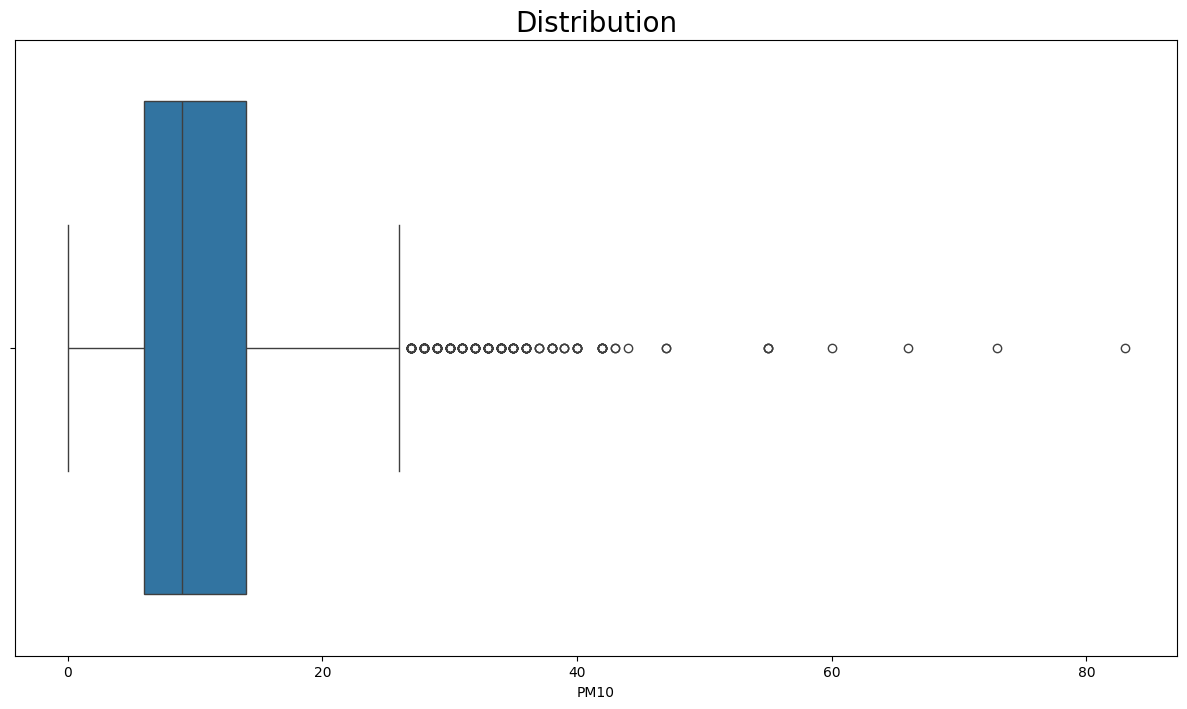

In [41]:
# box plot of the PM10
plt.figure(figsize = (15,8))
ax = sns.boxplot(x=data5['PM10'], whis=1.5)
plt.title('Distribution', fontsize=20)


From the boxplot we can clearly see that the data in this column is skewed, with many outliers on the skewed side of the data. But should we eliminate these data points from our study? Are they mistakes? Or, are they important values? It looks like the outliers are the result of how skewed the data is. Therefore, they represent the worst air quality with respect to PM10, not errors. These data points will likely be very important to our study, we don't want to remove them.

Let's use a violin plot to see a bit more about the shape of our data.

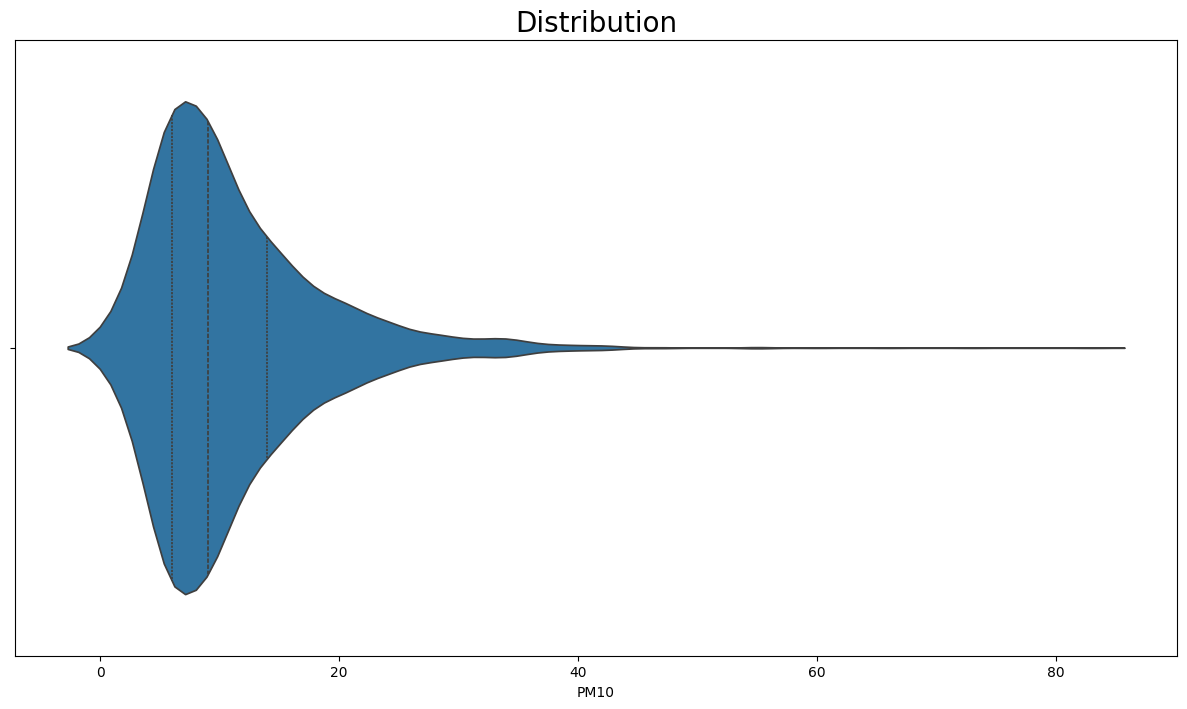

In [42]:
plt.figure(figsize=(15, 8))
sns.violinplot(x=data5['PM10'], inner='quartiles')
plt.title('Distribution', fontsize=20)
plt.show()

### Quartiles, Inter-quartile Range, and Outlier Selection

Both the boxplot and violin plot indicate the first (Q1) and third (Q3) quartiles, as well as the median. Q1 is the value under which 25% of data points are found. Q3 is the value under which 75% of data points are found. The difference between Q1 and Q3 is called the inter-quartile range (IQR).

A data point is typically considered an outlier if it is:
* smaller than Q1 - 1.5 * IQR
* greater than Q3 + 1.5 * IQR

Seaborn plots the whiskers at Q1 - **1.5** * IQR and Q3 + **1.5** * IQR by default, but this can be changed manually. Using this, we can calculate the associated values ourselves and select the data points considered as outliers.

In [43]:
# Calculate metrics describing distribution
Q1 = data5['PM10'].quantile(0.25)
Q3 = data5['PM10'].quantile(0.75)
IQR = Q3 - Q1

lowerBound = Q1 - 1.5 * IQR
upperBound = Q3 + 1.5 * IQR

In [44]:
selection = data5.loc[(data4['PM10']<= lowerBound) | (data4['PM10']>= upperBound)]

In [45]:
selection.info()

<class 'pandas.core.frame.DataFrame'>
Index: 210 entries, 418 to 11128
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Unnamed: 0.1  210 non-null    int64  
 1   PM10          210 non-null    float64
 2   CO            210 non-null    float64
 3   NO            210 non-null    float64
 4   NO2           210 non-null    float64
 5   O3            210 non-null    float64
 6   Date          210 non-null    object 
 7   Time          210 non-null    object 
 8   location      210 non-null    object 
dtypes: float64(5), int64(1), object(3)
memory usage: 16.4+ KB


### Cool Barplots - Average 'PM10' by Location and Number of 'PM10' Outliers by Location.


Text(0.5, 1.0, 'Average PM10 measurements by location')

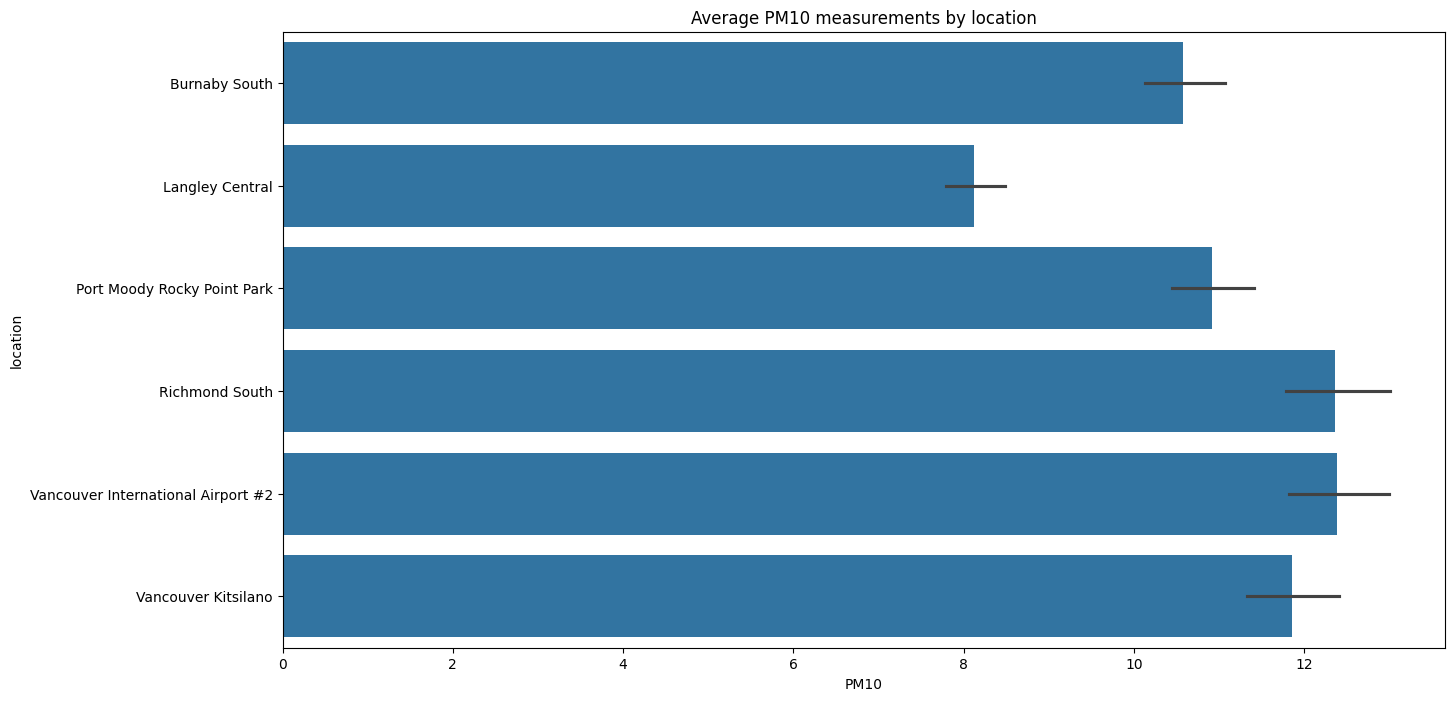

In [46]:
# Average PM10 measurements by location

plt.figure(figsize = (15,8))
ax = sns.barplot(data=data5, x='PM10', y="location", orient='h') # plots mean/average
ax.set_title("Average PM10 measurements by location")

Text(0.5, 1.0, 'Number of outliers by location')

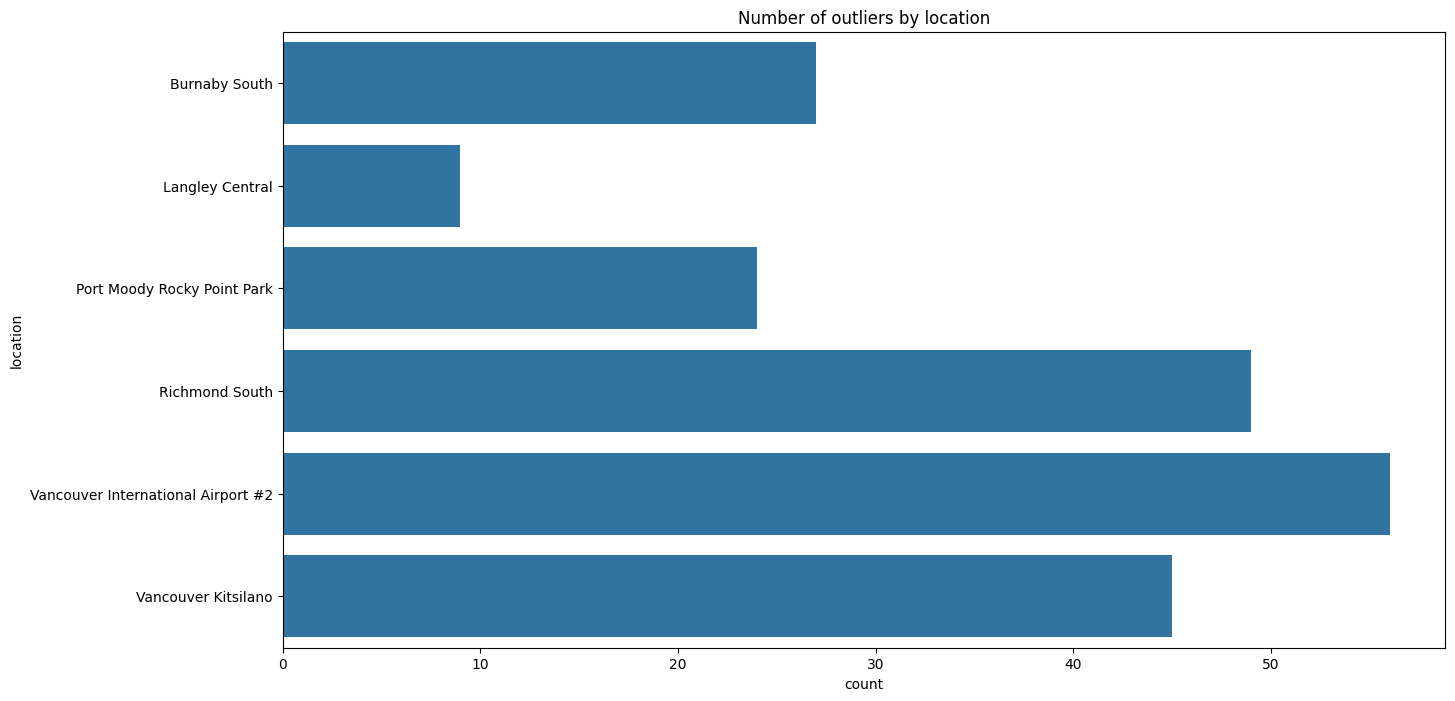

In [47]:
# Number of outliers by location

plt.figure(figsize = (15,8))
ax = sns.countplot(data=selection, y='location') # plots counts
ax.set_title("Number of outliers by location")

Now, let's look at the other four columns CO, NO, NO2, and O3.

In this section we will deal with all four columns at once, so the code will get a bit more complicated.

What we will do is:
1. Plot boxplots for all four variables.
2. Calculate Q1, Q3, IQR, lower boundary and upper boundary for three variables. Based on the boxplots we can skip one variable, because it does not include any outliers! :)
3. Create a subset of the original dataframe by selecting data points that are 'outliers' for each variable.
4. The boxplots indicated that for one of the variables the outliers were likely errors, rather than a skewed data distribution seen for the other variables. Remove these from the appropriate subset. After this is done, select the data points that are not outliers for the new data subset. Use this for the last question.
5. Create three countplots, showing the number of outliers by location.



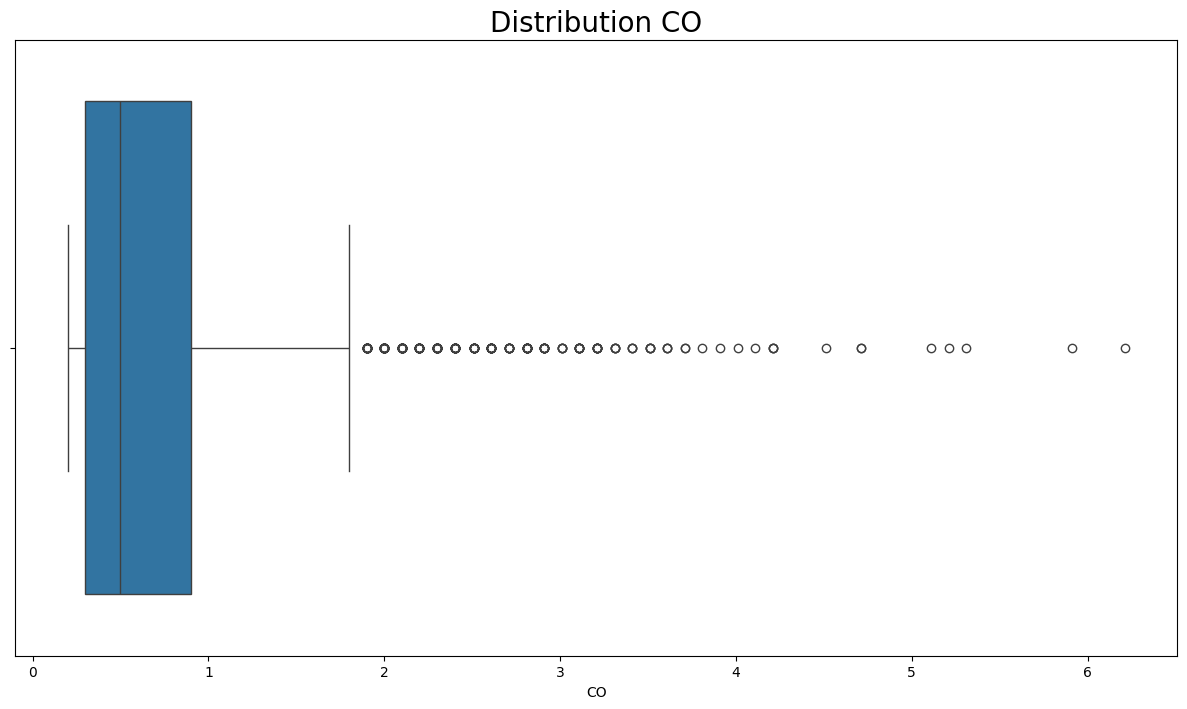

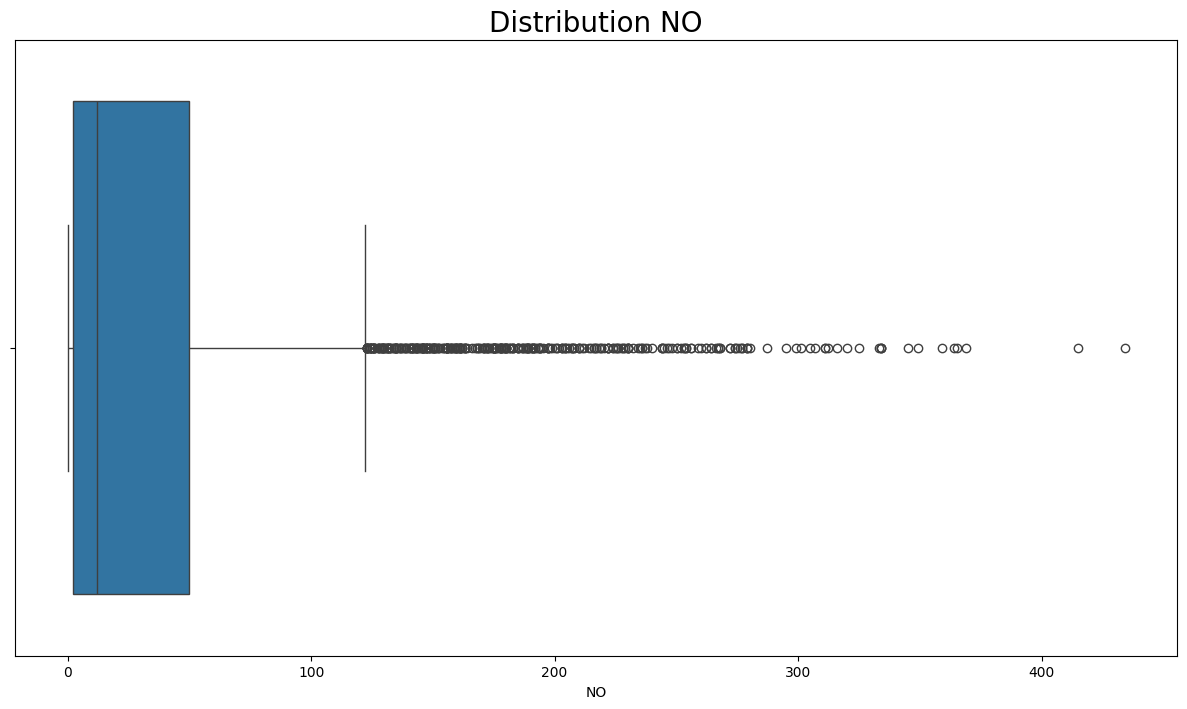

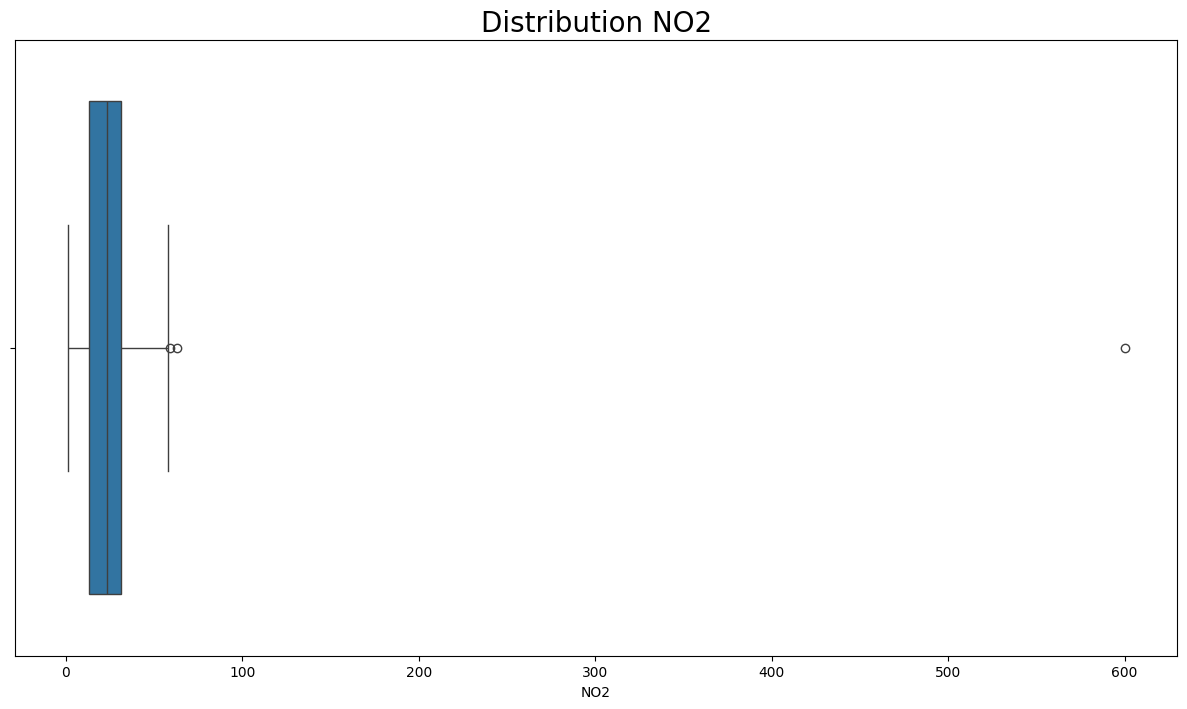

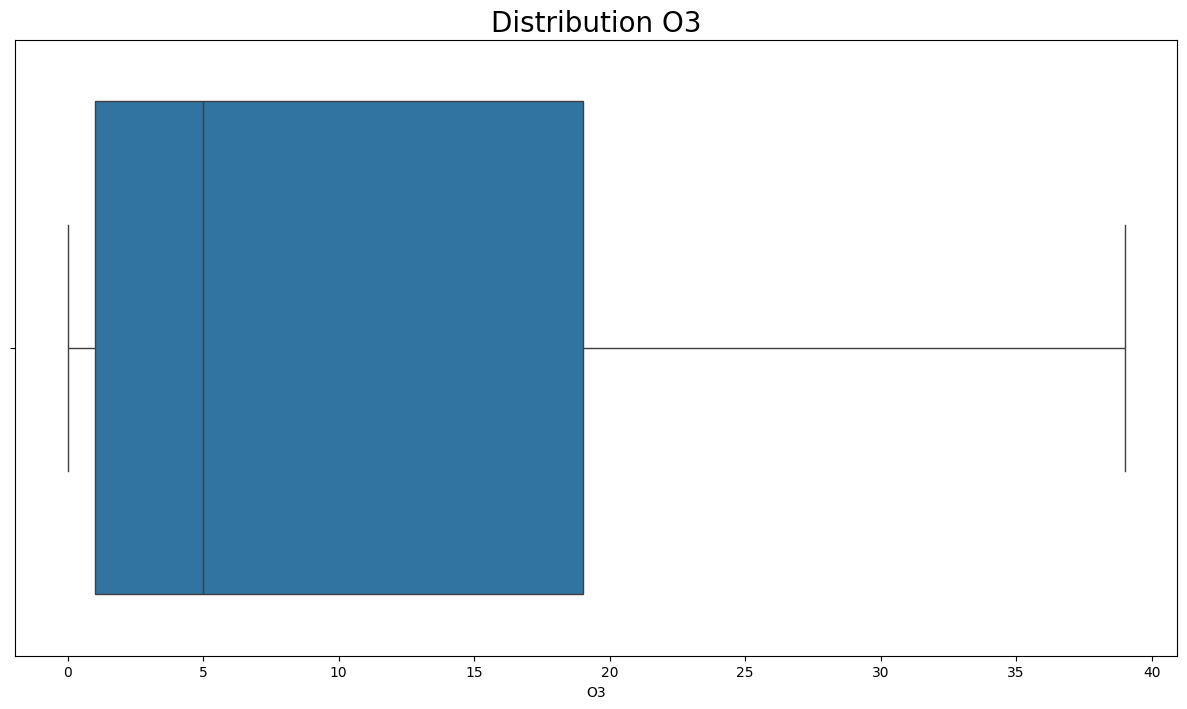

In [48]:
# Plot boxplots for all four variables.
# Solution 1: Option 1 plotting through loop

variables = ['CO', 'NO', 'NO2','O3']

for var in variables:
    plt.figure(figsize = (15,8))
    ax = sns.boxplot(x=data5[var], whis=1.5)
    plt.title('Distribution '+var, fontsize=20)

Text(0.5, 1.0, 'Distribution O3')

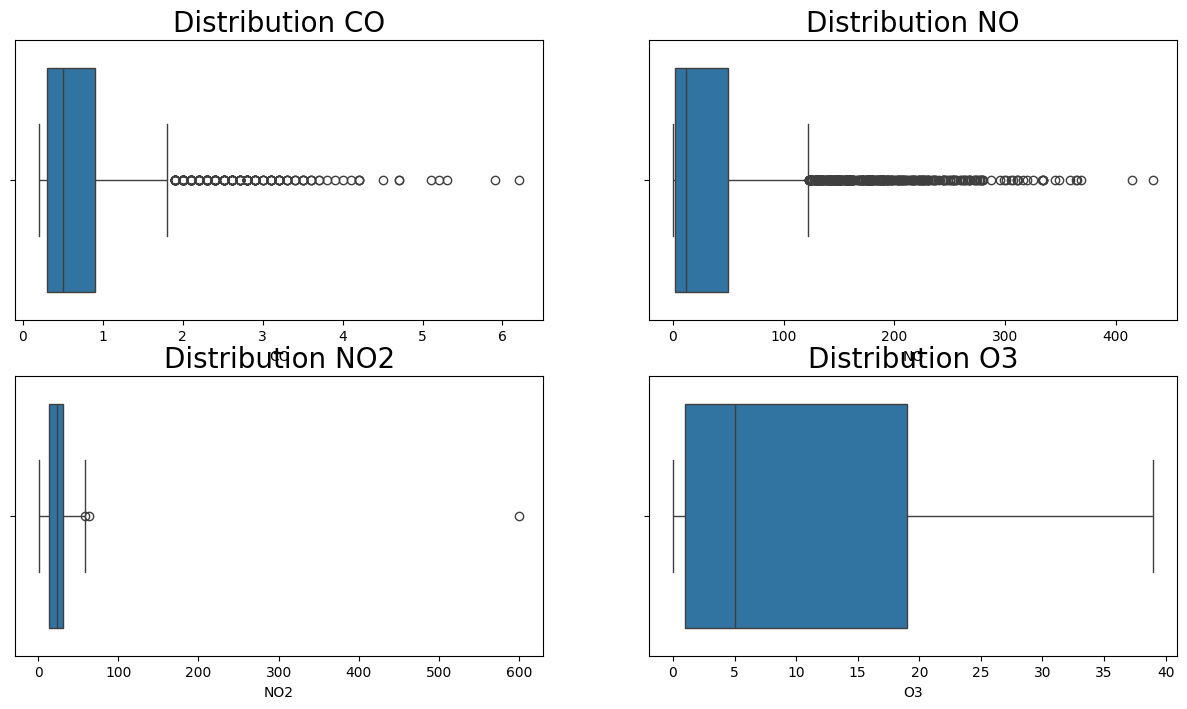

In [49]:
# Plot boxplots for all four variables.
# Solution 2: plotting using a grid
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(15,8))

# ax 0
sns.boxplot(ax=axes[0,0], x=data5['CO'], whis=1.5)
axes[0,0].set_title('Distribution '+'CO', fontsize=20)

# # ax 1
sns.boxplot(ax=axes[0,1], x=data5['NO'], whis=1.5)
axes[0,1].set_title('Distribution '+'NO', fontsize=20)

# # ax 2
sns.boxplot(ax=axes[1,0], x=data5['NO2'], whis=1.5)
axes[1,0].set_title('Distribution '+'NO2', fontsize=20)

# # ax 3
sns.boxplot(ax=axes[1,1], x=data5['O3'], whis=1.5)
axes[1,1].set_title('Distribution '+'O3', fontsize=20)

In [50]:
# 2. Calculate Q1, Q3, IQR, lower boundary and upper boundary for all four variables. (We excluded 'O3' since it does not contain any outliers)
# Solution

variables = ['CO', 'NO', 'NO2']

lowerBounds = []
upperBounds = []

for var in variables:
    Q1 = data5[var].quantile(0.25)
    Q3 = data5[var].quantile(0.75)
    IQR = Q3 - Q1

    lowerBounds.append(Q1 - 1.5 * IQR)
    upperBounds.append(Q3 + 1.5 * IQR)

print(lowerBounds)
print(upperBounds)

[np.float64(-0.6000000000000001), np.float64(-70.0), np.float64(-14.0)]
[np.float64(1.8000000000000003), np.float64(122.0), np.float64(58.0)]


In [51]:
# 3. Select data points that are 'outliers' for each variable. This results in four subsets of the original dataframe.

# Solution

selections = []
for i in range(len(variables)):
    var = variables[i]
    lowerBound = lowerBounds[i]
    upperBound = upperBounds[i]

    print(var)
    selections.append(data5.loc[(data5[var]<= lowerBound) | (data5[var]>= upperBound)])


CO
NO
NO2


In [52]:
# 4. The boxplots indicated that for one of the variables the outliers were likely errors, rather than a skewed data distribution seen for the other variables.
# Remove these from the appropriate subset. After this is done, select the data points that are outliers for the new data subset. Use this for the last question.

# Solution

selectionNO2 = data4.loc[(data5['NO2']> lowerBounds[2]) | (data5['NO2']< lowerBounds[2])] # note that conditional statement has changed.

Q1 = selectionNO2['NO2'].quantile(0.25)
Q3 = selectionNO2['NO2'].quantile(0.75)
IQR = Q3 - Q1

lowerBound = (Q1 - 1.5 * IQR)
upperBound = (Q3 + 1.5 * IQR)


selections[2] = selectionNO2.loc[(data5[var]<= lowerBound) | (data5[var]>= upperBound)] # replace subset in list with new subset

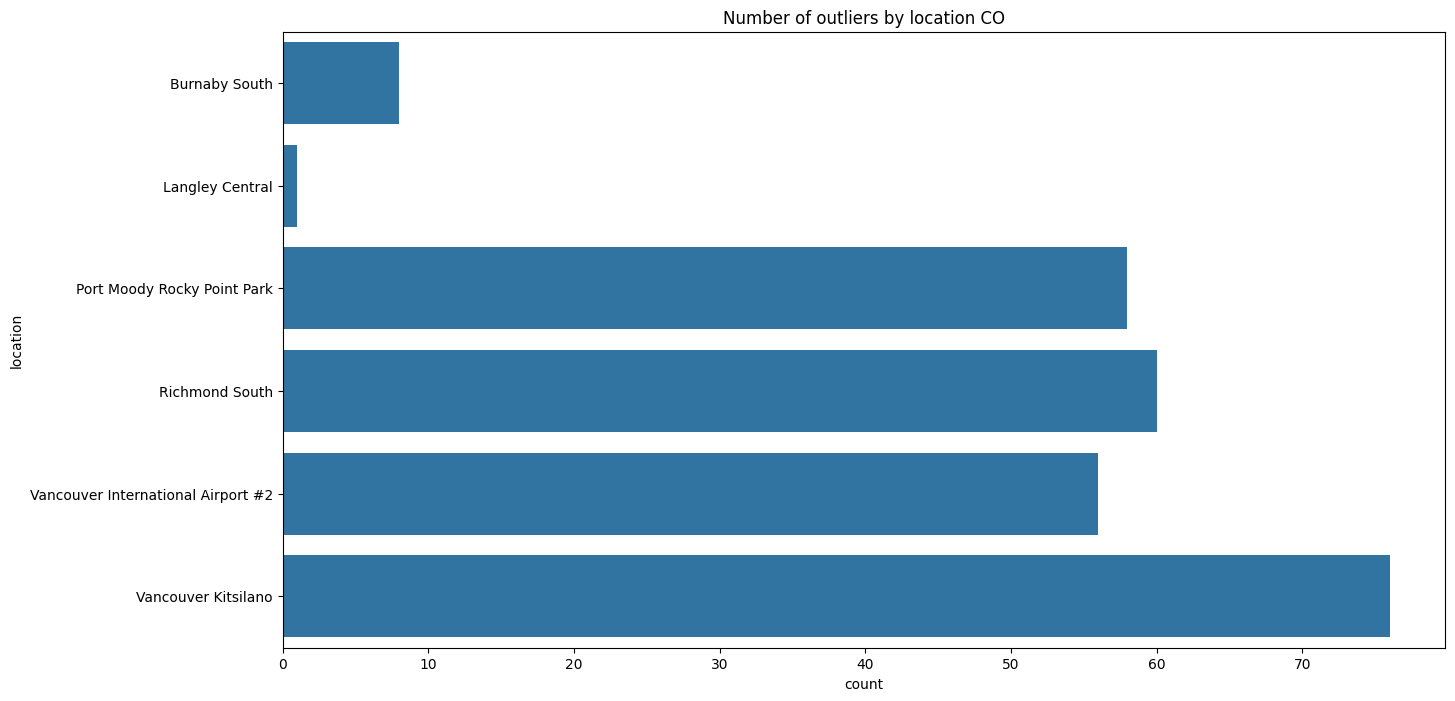

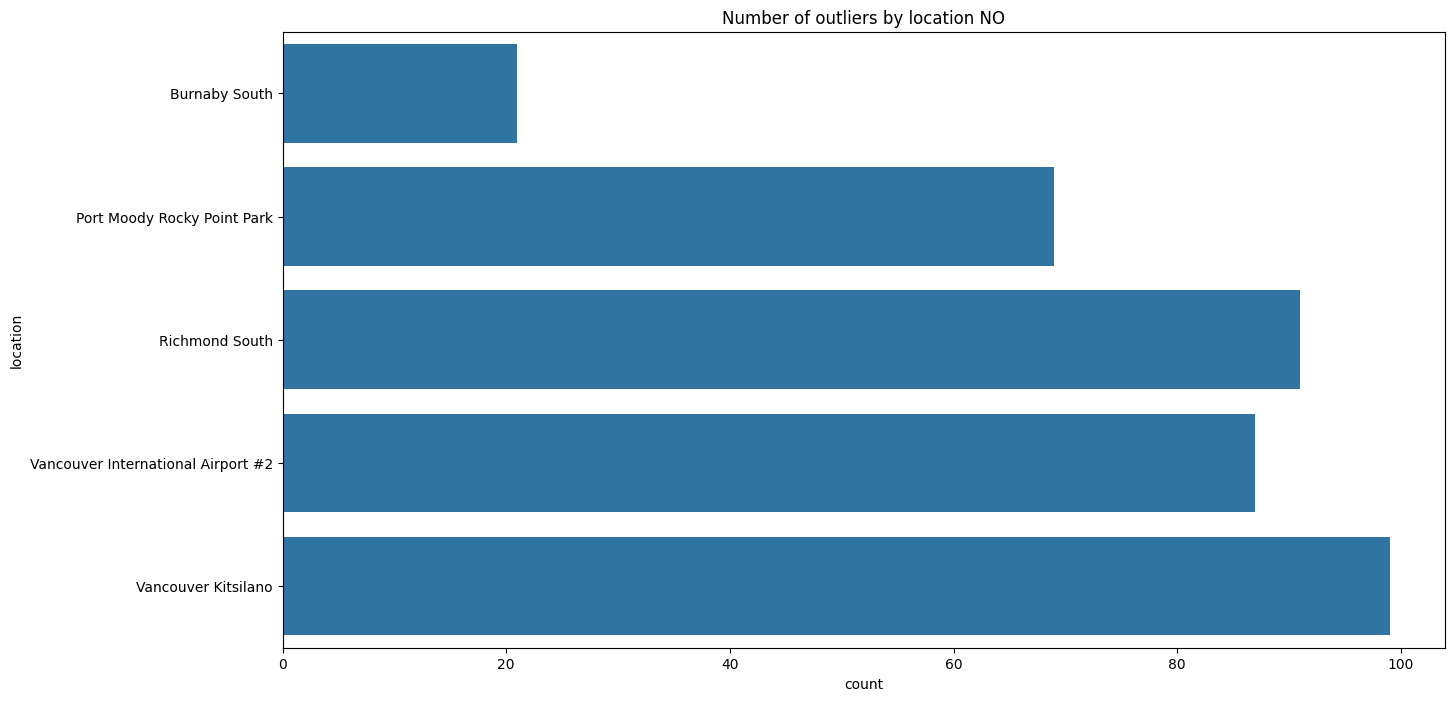

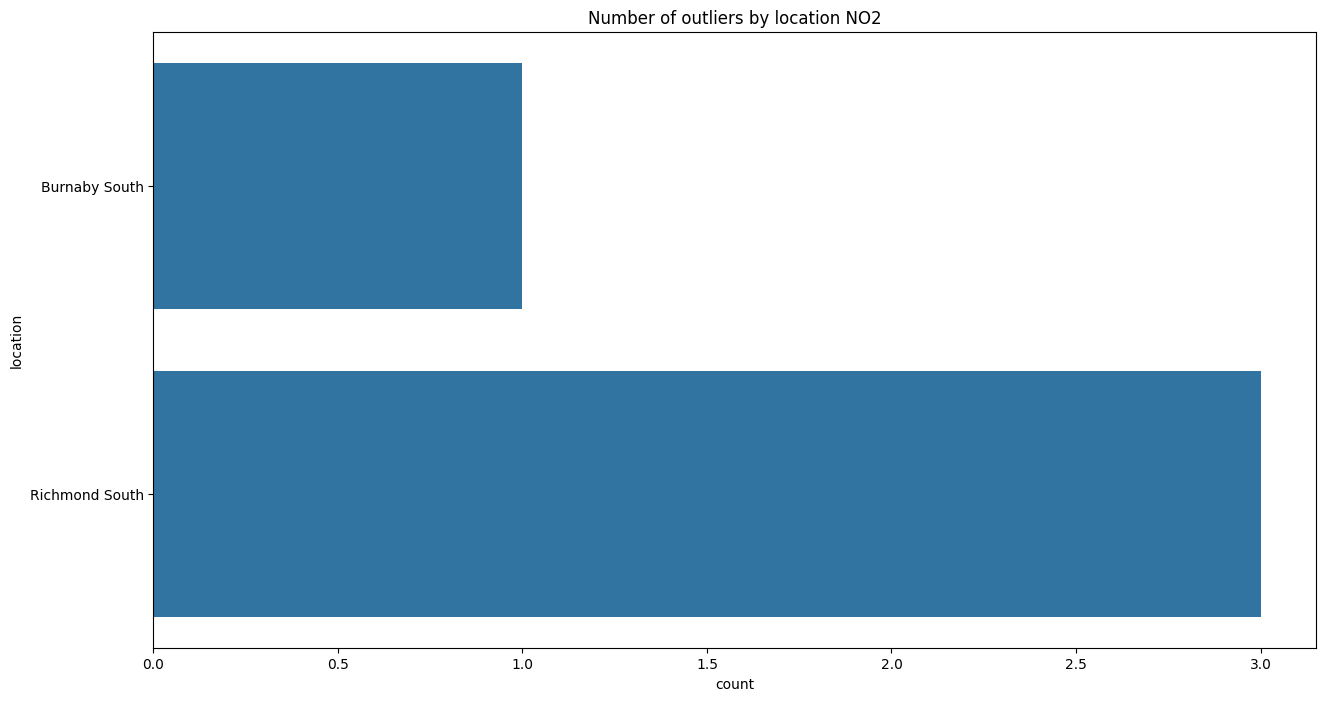

In [53]:
# 5. Create three countplots, showing the number of outliers by location.

# Solution
for i in range(len(variables)):
    plt.figure(figsize = (15,8))
    ax = sns.countplot(data=selections[i], y='location') # plots counts
    ax.set_title("Number of outliers by location "+variables[i])

# 4. Data Exploration and Summarization

In looking for outliers we have already started exploring our data. However, in this short section we will do so more explicitly using a date line graph to check out the daily NO2 measures.

First, let's plot the average NO2 measures by day and location using a line plot.

In [54]:
# convert Date to datetime format
data5['Date'] = pd.to_datetime(data5['Date'])

In [55]:
# 1. Solution part A
data5Group = data5.groupby(['Date','location'], as_index=False)['NO2'].mean() # groupby based on two columns
data5Group.head()

,Date,location,NO2
0,2000-01-01,Burnaby South,16.583333
1,2000-01-01,Langley Central,5.166667
2,2000-01-01,Port Moody Rocky Point Park,14.333333
3,2000-01-01,Richmond South,13.416667
4,2000-01-01,Vancouver International Airport #2,15.250000


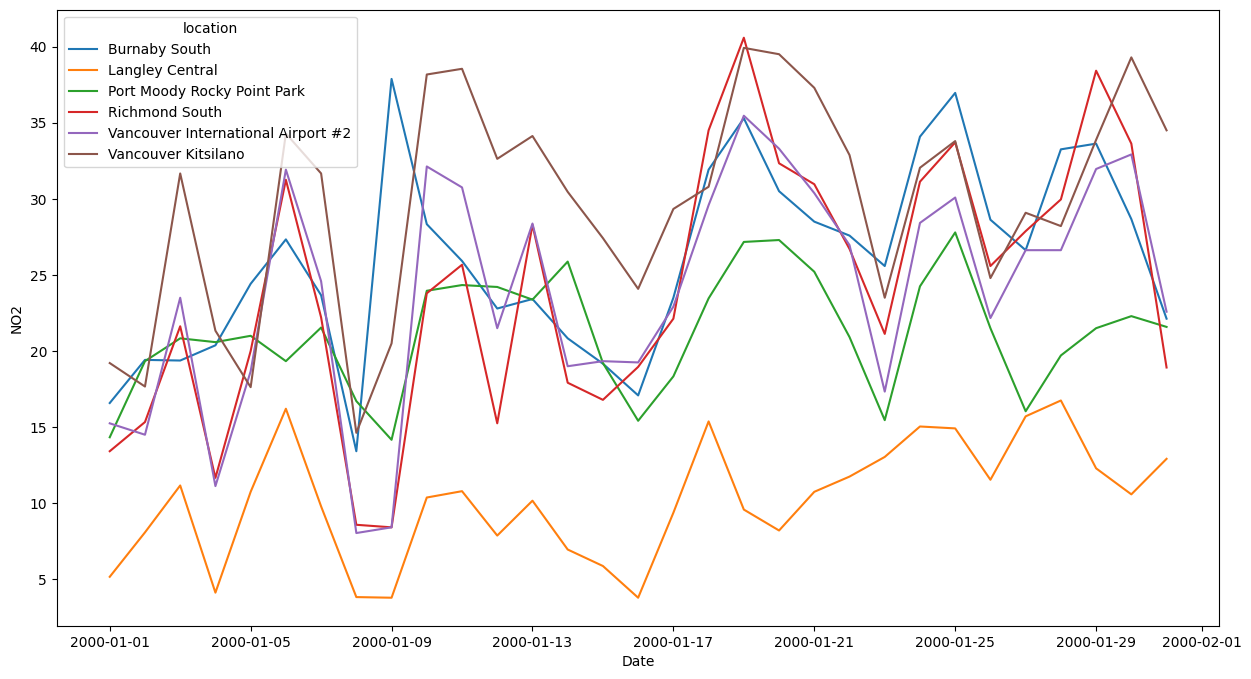

In [56]:
# 1. Solution part B
plt.figure(figsize = (15,8))
ax = sns.lineplot(data=data5Group, x='Date', y='NO2', hue='location')

### Question 3: Plot the maximum NO2 measures by day and location using a line plot. This should indicate where and when the outlier was recorded.

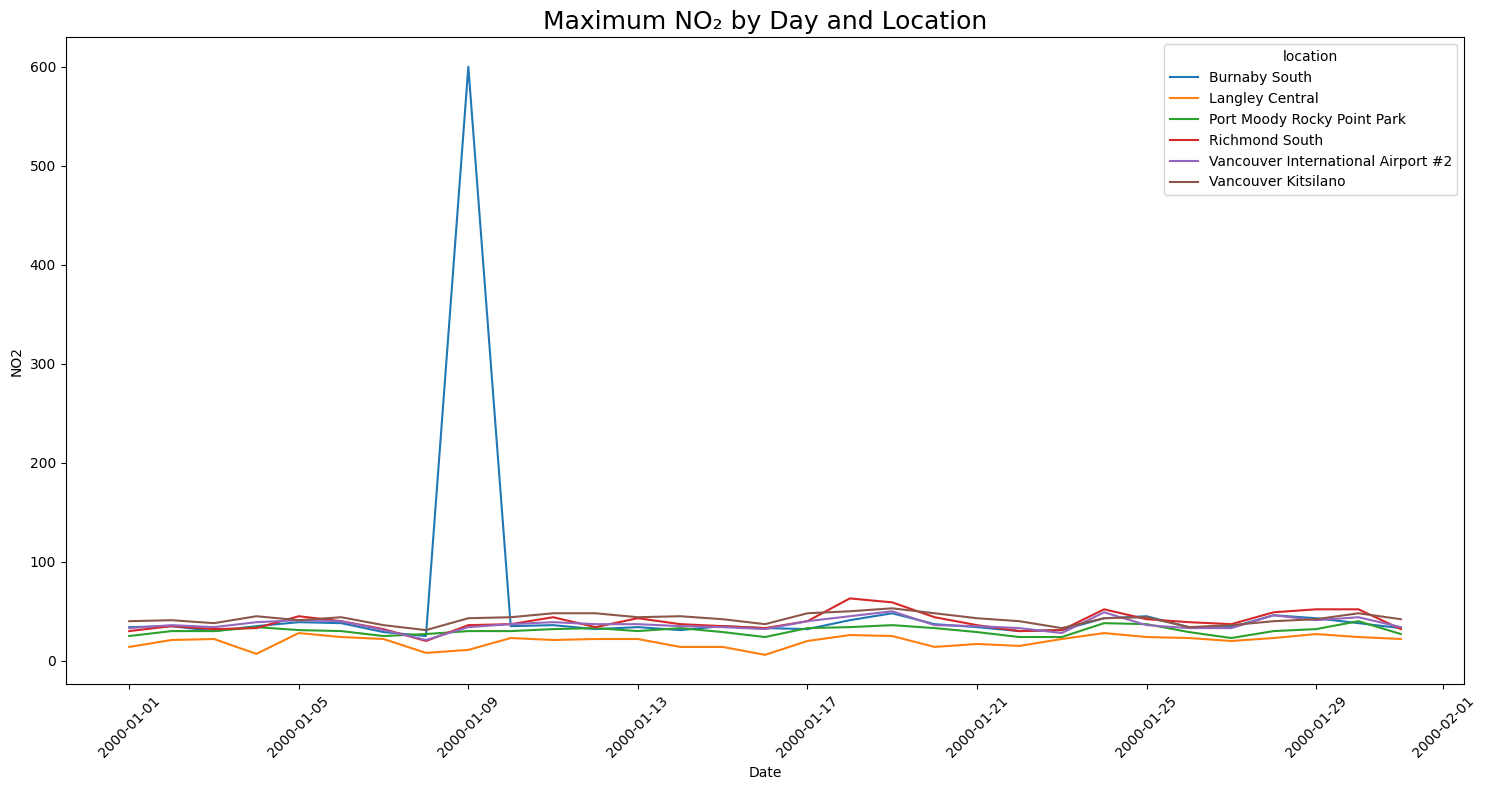

In [57]:
# answer here:
data5Group = (
    data5.groupby(['Date', 'location'])['NO2']
         .max()
         .reset_index()
)

plt.figure(figsize=(15, 8))
ax = sns.lineplot(data=data5Group, x='Date', y='NO2', hue='location')
plt.title('Maximum NO₂ by Day and Location', fontsize=18)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [58]:
data5.to_csv('airdata3_clean.csv')